# Week 5 - Task 5: Mini Project — Handwritten Digit Recognition with a Neural Network
**Deep Learning & Neural Networks | AI Internship**

## 1. Problem Statement
Computers must read handwritten numbers in many places, for example postal codes on letters and amounts on bank cheques. In this project I build an Artificial Neural Network that looks at an image of a handwritten digit and predicts which number (0 to 9) it is.

## 2. Dataset Description
**Optical Recognition of Handwritten Digits dataset** — 1,797 images of handwritten digits, each image is 8x8 pixels (64 pixel values from 0 to 16), and the label is the digit 0-9. *Source: UCI Machine Learning Repository, loaded through scikit-learn (`load_digits`) and saved as `digits.csv`. This is a smaller version of the MNIST idea (MNIST has 28x28 images).*

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
tf.keras.utils.set_random_seed(42)   # same results every time I run
os.makedirs("Screenshots", exist_ok=True)
import matplotlib.pyplot as plt
# small helper: saves printed text as a picture to use as a screenshot
def save_output_image(text, filename):
    lines = text.split("\n")
    fig = plt.figure(figsize=(10, 0.28*len(lines)+0.6))
    fig.text(0.02, 0.98, text, family="monospace", fontsize=9, va="top")
    fig.savefig(filename, dpi=130, bbox_inches="tight", facecolor="white")
    plt.close(fig)

I0000 00:00:1791714963.872791    5356 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791714965.340206    5356 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 3. Load the Data

In [2]:
df = pd.read_csv("digits.csv")
print("Shape:", df.shape)
df.head()

Shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


## 4. Data Preprocessing

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print()
print("Images per digit:")
print(df["digit"].value_counts().sort_index())

Missing values: 0
Duplicate rows : 0

Images per digit:
digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


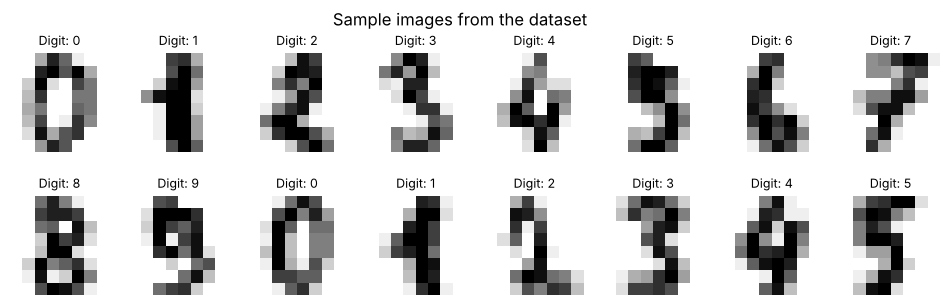

In [4]:
# look at some images
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(df.iloc[i, :64].values.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Digit: {int(df.iloc[i, 64])}", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample images from the dataset")
plt.savefig("Screenshots/01_sample_images.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
# features and target
X = df.drop(columns="digit").values / 16.0     # pixel values are 0-16, so divide by 16 to get 0-1
y = df["digit"].values

# train/test split (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Pixel range after scaling:", X.min(), "to", X.max())

Train: (1437, 64)  Test: (360, 64)
Pixel range after scaling: 0.0 to 1.0


The pixels are scaled to the 0-1 range by dividing by 16 (the maximum pixel value). The split uses `stratify` so every digit has a fair share in the train and test sets.

## 5. Neural Network Architecture
- **Input layer:** 64 neurons (one per pixel)
- **Hidden layer 1:** 128 neurons, ReLU
- **Dropout:** 20% (randomly switches off neurons while training to reduce overfitting)
- **Hidden layer 2:** 64 neurons, ReLU
- **Output layer:** 10 neurons, Softmax (one per digit)

In [6]:
model = keras.Sequential([
    keras.Input(shape=(64,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

lines = []
model.summary(print_fn=lambda s: lines.append(s))
save_output_image("\n".join(lines), "Screenshots/02_model_summary.png")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Model Training
40 epochs, batch size 32, and 20% of the training data for validation.

In [7]:
history = model.fit(X_train, y_train, epochs=40, batch_size=32, validation_split=0.2, verbose=0)
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
hist.to_csv("training_history.csv", index_label="epoch")

rows = [f"Epoch {e:2d}/40 - loss: {hist.loc[e,'loss']:.4f} - accuracy: {hist.loc[e,'accuracy']:.4f} - val_loss: {hist.loc[e,'val_loss']:.4f} - val_accuracy: {hist.loc[e,'val_accuracy']:.4f}"
        for e in [1, 2, 3, 5, 10, 15, 20, 25, 30, 35, 40]]
print("\n".join(rows))
save_output_image("TRAINING OUTPUT (selected epochs)\n" + "\n".join(rows), "Screenshots/03_training_output.png")

Epoch  1/40 - loss: 1.9733 - accuracy: 0.4726 - val_loss: 1.5081 - val_accuracy: 0.7500
Epoch  2/40 - loss: 1.0950 - accuracy: 0.7998 - val_loss: 0.7335 - val_accuracy: 0.8750
Epoch  3/40 - loss: 0.5688 - accuracy: 0.8808 - val_loss: 0.4524 - val_accuracy: 0.9028
Epoch  5/40 - loss: 0.2791 - accuracy: 0.9312 - val_loss: 0.2798 - val_accuracy: 0.9167
Epoch 10/40 - loss: 0.1344 - accuracy: 0.9643 - val_loss: 0.1797 - val_accuracy: 0.9444
Epoch 15/40 - loss: 0.0870 - accuracy: 0.9774 - val_loss: 0.1502 - val_accuracy: 0.9479
Epoch 20/40 - loss: 0.0625 - accuracy: 0.9843 - val_loss: 0.1390 - val_accuracy: 0.9514
Epoch 25/40 - loss: 0.0428 - accuracy: 0.9904 - val_loss: 0.1442 - val_accuracy: 0.9444
Epoch 30/40 - loss: 0.0311 - accuracy: 0.9922 - val_loss: 0.1360 - val_accuracy: 0.9549
Epoch 35/40 - loss: 0.0235 - accuracy: 0.9956 - val_loss: 0.1234 - val_accuracy: 0.9514
Epoch 40/40 - loss: 0.0210 - accuracy: 0.9939 - val_loss: 0.1124 - val_accuracy: 0.9479


## 7. Accuracy & Loss Graphs

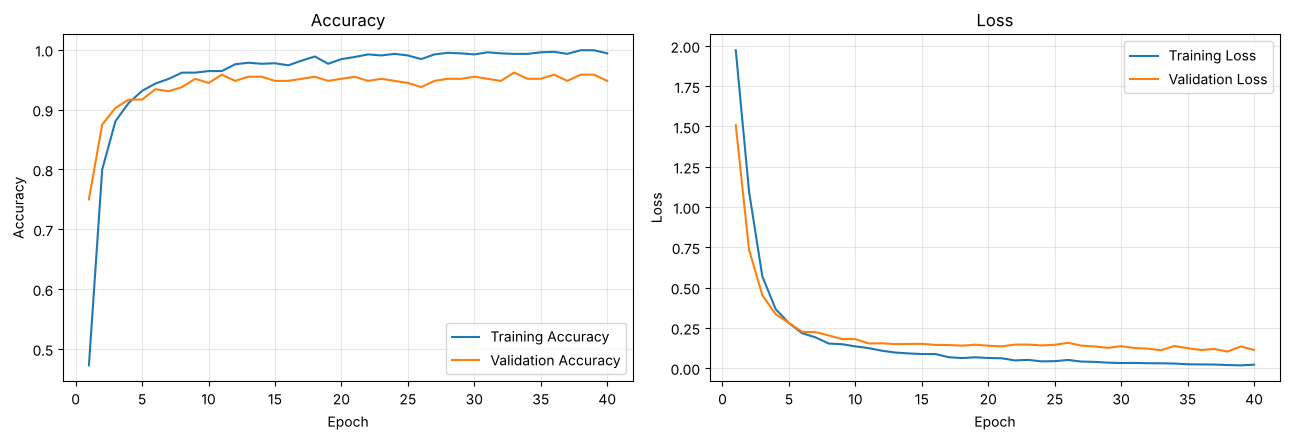

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.index, hist["accuracy"], label="Training Accuracy")
axes[0].plot(hist.index, hist["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist.index, hist["loss"], label="Training Loss")
axes[1].plot(hist.index, hist["val_loss"], label="Validation Loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Screenshots/04_accuracy_loss_graphs.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Predictions

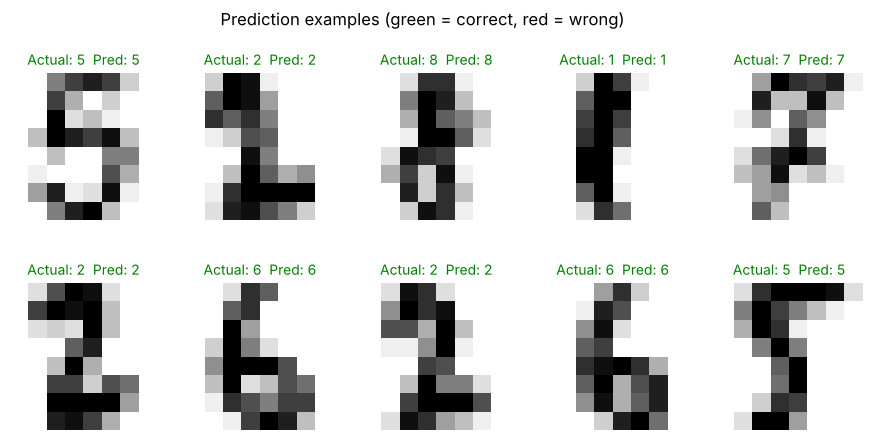

In [9]:
probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(probs, axis=1)

pred_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred, "Confidence_%": (probs.max(axis=1)*100).round(1)})
pred_df["Correct"] = np.where(pred_df["Actual"] == pred_df["Predicted"], "Yes", "No")
pred_df.to_csv("predictions.csv", index=False)

# show 10 test images with their prediction
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    color = "green" if y_pred[i] == y_test[i] else "red"
    ax.set_title(f"Actual: {y_test[i]}  Pred: {y_pred[i]}", color=color, fontsize=10)
    ax.axis("off")
plt.suptitle("Prediction examples (green = correct, red = wrong)")
plt.savefig("Screenshots/05_prediction_examples.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Model Evaluation

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
report = classification_report(y_test, y_pred)
out = (f"Test loss     : {test_loss:.4f}\nTest accuracy : {test_acc*100:.2f}%\n\n" + report)
print(out)
save_output_image("MODEL EVALUATION\n" + out, "Screenshots/06_evaluation.png")

Test loss     : 0.0739
Test accuracy : 97.50%

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
           2       0.97      1.00      0.99        35
           3       1.00      0.97      0.99        37
           4       1.00      1.00      1.00        36
           5       0.97      1.00      0.99        37
           6       0.97      0.97      0.97        36
           7       0.92      1.00      0.96        36
           8       0.97      0.89      0.93        35
           9       1.00      0.94      0.97        36

    accuracy                           0.97       360
   macro avg       0.98      0.97      0.97       360
weighted avg       0.98      0.97      0.97       360



## 10. Confusion Matrix

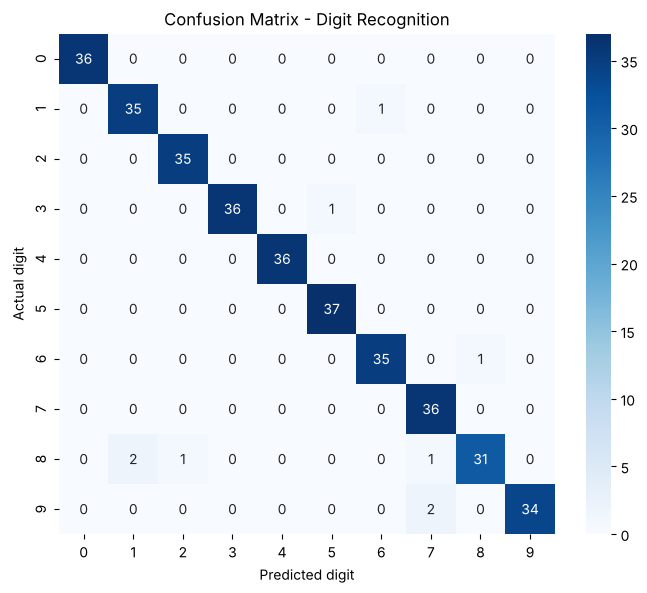

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title("Confusion Matrix - Digit Recognition")
plt.savefig("Screenshots/07_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

Wrong predictions: 9 out of 360
     Actual  Predicted  Confidence_% Correct
36        6          8     54.700001      No
51        8          1     98.900002      No
93        9          7     54.599998      No
127       8          1     77.300003      No
145       9          7     54.500000      No
168       3          5     56.000000      No
228       1          6     38.700001      No
254       8          2     49.299999      No
276       8          7     39.000000      No


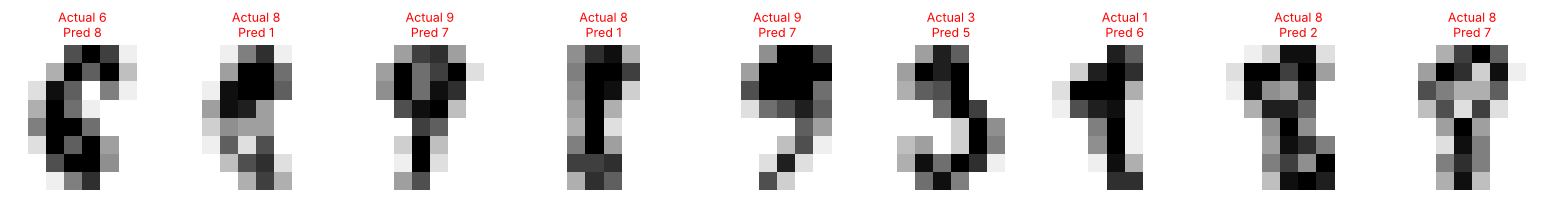

In [12]:
# which digits were predicted wrong?
wrong = pred_df[pred_df["Correct"] == "No"]
print("Wrong predictions:", len(wrong), "out of", len(pred_df))
print(wrong.to_string())

fig, axes = plt.subplots(1, max(len(wrong), 2), figsize=(2.2*max(len(wrong), 2), 2.8))
for ax, idx in zip(np.ravel(axes), wrong.index):
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Actual {y_test[idx]}\nPred {y_pred[idx]}", color="red", fontsize=9)
    ax.axis("off")
plt.savefig("Screenshots/08_wrong_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Final Conclusion

I built a neural network that recognises handwritten digits with **97.50% test accuracy** (351 of 360 test images correct). The model learned quickly: validation accuracy was about 92% after 5 epochs and 95% after 20 epochs. The digit **8** was the hardest (recall 89%), and 4 of the 9 mistakes were real 8s predicted as 1, 2 or 7. This is understandable because an 8 looks like a 3, 5 or 6 in a tiny 8x8 image. The model was also unsure on most of its mistakes (confidence below 60% on 7 of the 9), which shows the mistakes were hard images and not random errors. The neural network is a good solution for this problem.

---
## Project Report (250-400 words)

**Problem being solved:** Many systems, like postal code readers and cheque scanners, need to recognise handwritten numbers. In this project I built a neural network that looks at an image of a handwritten digit and predicts the number from 0 to 9.

**Dataset:** I used the Optical Recognition of Handwritten Digits dataset from the UCI Machine Learning Repository, loaded through scikit-learn. It has 1,797 images of 8x8 pixels, so each image gives 64 pixel values, and there are about 180 images for every digit. There were no missing values or duplicates. I divided the pixel values by 16 to scale them between 0 and 1 and split the data 80% for training and 20% for testing.

**Neural network architecture:** The network has an input layer of 64 neurons, a hidden layer of 128 neurons with ReLU, a Dropout layer of 20% to reduce overfitting, a second hidden layer of 64 neurons with ReLU, and an output layer of 10 neurons with Softmax. I used the Adam optimizer and sparse categorical crossentropy loss.

**Training process:** The model was trained for 40 epochs with batch size 32, and 20% of the training data was kept for validation. Training accuracy went from 47% to about 99%, and validation accuracy stayed near 95%.

**Results:** On 360 unseen test images the model reached 97.50% accuracy. The confusion matrix shows that most digits were recognised perfectly. Only 9 images were wrong, and the digit 8 was the most difficult one.

**Limitations:** The images are very small (8x8), so some digits look alike. The model also shows a small gap between training accuracy (99%) and validation accuracy (95%), which is a mild sign of overfitting. It was tested on only one split of one dataset.

**Future improvements:** I want to use the full MNIST dataset (28x28 images) and a Convolutional Neural Network (CNN), which is better for images. I can also add early stopping, tune the number of neurons, and test with my own handwriting.